# Judging Books by Their Covers

In [2]:
import pandas as pd

df = pd.read_csv('data/books.csv', sep=';', encoding='latin1', escapechar='\\')
books_features = pd.read_csv('data/books_features.csv', low_memory=False)
ratings = pd.read_csv('data/ratings.csv', sep=';', encoding='latin1', escapechar='\\')
users = pd.read_csv('data/users.csv', sep=';', encoding='latin1', escapechar='\\')

sample = df.sample(300)
print(len(df))

# sample.to_csv('data/book_sample.csv', index=False, sep=';', encoding='latin1', escapechar='\\')

df.head()

271379


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


Extracted features. 96285 errors? All 1x1 pixel images?

In [3]:
books_features.head()



,isbn,error,color1_hex,color1_pct,color2_hex,color2_pct,color3_hex,color3_pct,text_color_hex,text_color_conf,contrast_rms,contrast_wcag_p5_p95,contrast_top2_deltaE,edge_density,mean_gradient,hf_energy_ratio,color_entropy,mean_lightness,mean_saturation,colorfulness
0,0002005018,NaN,#3d342d,0.2099,#d2694d,0.2067,#a35e4e,0.1830,#d99772,0.392,0.2099,10.363,57.45,0.2406,0.0573,0.3535,6.899,0.5102,0.4249,0.2685
1,0374157065,NaN,#efeead,0.3233,#f3f5d9,0.2920,#e2dc72,0.1636,#34424b,0.887,0.2254,9.954,18.95,0.3344,0.0832,0.1741,7.162,0.8187,0.2990,0.2273
2,0195153448,NaN,#baa68e,0.6376,#3f2b21,0.0974,#856a5b,0.0710,#140e0f,0.524,0.2160,8.339,49.88,0.2275,0.0474,0.1519,4.002,0.5540,0.2980,0.0972
3,0671870432,NaN,#15151a,0.4733,#30302b,0.1755,#b29d4f,0.1227,#dcddd4,0.908,0.2603,10.865,14.34,0.4561,0.1017,0.1752,5.661,0.2691,0.3542,0.1508
4,0425176428,NaN,#070404,0.6389,#3a3734,0.1052,#79716c,0.0807,#d8ccc4,0.986,0.2338,8.983,21.89,0.4051,0.0950,0.3698,3.744,0.1535,0.3252,0.1004


## Merge and clean datasets

In [4]:
# Rename 'isbn' to 'ISBN' in books_features to match the main dataframe
books_features = books_features.rename(columns={'isbn': 'ISBN'})

# Merge the books data with the extracted cover features
merged_df = pd.merge(df, books_features, on='ISBN', how='inner')

# Drop the 1x1 pixel image errors you identified
merged_df = merged_df[merged_df['error'].isna()]

# Ensure we only keep rows that successfully extracted all three colors
merged_df = merged_df.dropna(subset=['color1_hex', 'color2_hex', 'color3_hex'])

print(f"Total usable books: {len(merged_df)}")
merged_df[['ISBN', 'Book-Title', 'color1_hex', 'color2_hex', 'color3_hex']].head()

Total usable books: 174687


,ISBN,Book-Title,color1_hex,color2_hex,color3_hex
0,0195153448,Classical Mythology,#baa68e,#3f2b21,#856a5b
1,0002005018,Clara Callan,#3d342d,#d2694d,#a35e4e
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,#efeead,#f3f5d9,#e2dc72
4,0393045218,The Mummies of Urumchi,#fcfbfa,#b6a9a0,#99644b
6,0425176428,What If?: The World's Foremost Military Histor...,#070404,#3a3734,#79716c


## Convert colors to usable numbers for bayes

In [5]:
import colorsys

def hex_to_hsv(hex_color):
    """Converts a hex color string (e.g., '#baa68e') to H, S, V components."""
    if pd.isna(hex_color):
        return pd.Series([None, None, None])
    
    # Remove '#' and convert to RGB values between 0 and 1
    hex_color = str(hex_color).lstrip('#')
    r, g, b = tuple(int(hex_color[i:i+2], 16) / 255.0 for i in (0, 2, 4))
    
    # Convert to HSV
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    return pd.Series([h, s, v])

# Apply the conversion function to each of the three color columns
print("Converting Color 1...")
merged_df[['H1', 'S1', 'V1']] = merged_df['color1_hex'].apply(hex_to_hsv)

print("Converting Color 2...")
merged_df[['H2', 'S2', 'V2']] = merged_df['color2_hex'].apply(hex_to_hsv)

print("Converting Color 3...")
merged_df[['H3', 'S3', 'V3']] = merged_df['color3_hex'].apply(hex_to_hsv)

print("Conversion complete!")
merged_df[['ISBN', 'Book-Title', 'H1', 'S1', 'V1', 'H2', 'S2', 'V2']].head()

Converting Color 1...
Converting Color 2...
Converting Color 3...
Conversion complete!


,ISBN,Book-Title,H1,S1,V1,H2,S2,V2
0,0195153448,Classical Mythology,0.090909,0.236559,0.729412,0.055556,0.476190,0.247059
1,0002005018,Clara Callan,0.072917,0.262295,0.239216,0.035088,0.633333,0.823529
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,0.164141,0.276151,0.937255,0.178571,0.114286,0.960784
4,0393045218,The Mummies of Urumchi,0.083333,0.007937,0.988235,0.068182,0.120879,0.713725
6,0425176428,What If?: The World's Foremost Military Histor...,0.000000,0.428571,0.027451,0.083333,0.103448,0.227451


In [6]:
import pandas as pd

# 1. Load the new dataset you uploaded
best_books_df = pd.read_csv('data/books_1.Best_Books_Ever.csv')

# Ensure the ISBN column matches our merged_df for joining
if 'isbn' in best_books_df.columns:
    best_books_df = best_books_df.rename(columns={'isbn': 'ISBN'})

# 2. Convert ISBN-10 to ISBN-13 so the datasets can actually match
def isbn10_to_isbn13(isbn10):
    isbn = str(isbn10).strip().upper()
    if len(isbn) != 10:
        return isbn 
        
    core = '978' + isbn[:-1]
    
    total = 0
    for i, digit in enumerate(core):
        if digit.isdigit():
            weight = 1 if i % 2 == 0 else 3
            total += int(digit) * weight
        else:
            return isbn 
            
    check_digit = 10 - (total % 10)
    if check_digit == 10:
        check_digit = 0
            
    return core + str(check_digit)

print("Converting ISBN-10s to ISBN-13s...")
merged_df['ISBN13'] = merged_df['ISBN'].apply(isbn10_to_isbn13)

# 3. Merge using the converted ISBNs
overlap_df = pd.merge(merged_df, best_books_df, left_on='ISBN13', right_on='ISBN', how='inner')
print(f"Total overlapping books between datasets: {len(overlap_df)}")

# 4. Clean and map the genres
def clean_genre(genre_str):
    if pd.isna(genre_str): return None
    g = str(genre_str).lower()
    
    if 'fantasy' in g or 'magic' in g: return 'Fantasy'
    if 'science fiction' in g or 'sci-fi' in g: return 'Sci-Fi'
    if 'mystery' in g or 'thriller' in g or 'suspense' in g or 'detective' in g: return 'Mystery/Thriller'
    if 'romance' in g or 'love' in g: return 'Romance'
    if 'history' in g or 'historical' in g: return 'History'
    if 'biography' in g or 'memoir' in g: return 'Biography'
    if 'religion' in g or 'philosophy' in g: return 'Religion/Philosophy'
    if 'fiction' in g: return 'General Fiction'
    return 'Other'

genre_col = 'genres' if 'genres' in overlap_df.columns else 'genre'
overlap_df['Genre'] = overlap_df[genre_col].apply(clean_genre)

# 5. Drop missing and 'Other' categories, keeping all remaining books
df_model = overlap_df.dropna(subset=['Genre'])
df_model = df_model[df_model['Genre'] != 'Other'].reset_index(drop=True)

print(f"\nFinal usable books for the model: {len(df_model)}")
print("\nFull Genre Distribution:")
print(df_model['Genre'].value_counts())

Converting ISBN-10s to ISBN-13s...
Total overlapping books between datasets: 7764

Final usable books for the model: 7661

Full Genre Distribution:
Genre
Fantasy                2190
History                1698
General Fiction        1062
Mystery/Thriller       1058
Romance                 830
Religion/Philosophy     410
Biography               314
Sci-Fi                   99
Name: count, dtype: int64


In [7]:
import pandas as pd

# 1. Load the new dataset
new_books_df = pd.read_csv('data/GoodReads_100k_books.csv', low_memory=False)

# Ensure the ISBN column is named correctly
if 'isbn' in new_books_df.columns:
    new_books_df = new_books_df.rename(columns={'isbn': 'ISBN'})

# 2. Convert ISBNs to ISBN-13 if necessary (assuming you already defined isbn10_to_isbn13 in the cell above)
if 'ISBN' in new_books_df.columns:
    new_books_df['ISBN'] = new_books_df['ISBN'].apply(isbn10_to_isbn13)

# 3. Merge the existing HSV features (merged_df) with the new dataset
new_overlap_df = pd.merge(merged_df, new_books_df, left_on='ISBN13', right_on='ISBN', how='inner')
print(f"Total overlapping books found in the new dataset: {len(new_overlap_df)}")

# 4. Clean and map the genres
# Adjust 'genre' to whatever the genre column is actually named in the Goodreads dataset (e.g., 'genre', 'genres', 'category')
genre_col_new = 'genres' if 'genres' in new_overlap_df.columns else 'genre' 
if genre_col_new in new_overlap_df.columns:
    new_overlap_df['Genre'] = new_overlap_df[genre_col_new].apply(clean_genre)

    # 5. Drop missing and 'Other' categories
    new_clean_df = new_overlap_df.dropna(subset=['Genre'])
    new_clean_df = new_clean_df[new_clean_df['Genre'] != 'Other']
    
    # 6. Combine this new data with your previous df_model
    # We only keep the columns we actually need for the model to prevent conflicts
    cols_to_keep = ['ISBN13', 'Book-Title', 'H1', 'S1', 'V1', 'H2', 'S2', 'V2', 'H3', 'S3', 'V3', 'Genre']
    
    # Check if df_model exists from your previous cell
    if 'df_model' in locals():
        df_model = pd.concat([df_model[cols_to_keep], new_clean_df[cols_to_keep]]).drop_duplicates(subset=['ISBN13']).reset_index(drop=True)
    else:
        df_model = new_clean_df[cols_to_keep].reset_index(drop=True)

    print(f"\nFinal combined usable books for the model: {len(df_model)}")
    print("\nUpdated Full Genre Distribution:")
    print(df_model['Genre'].value_counts())
else:
    print(f"\nCould not find a genre column in the new dataset. Please check the column names: {new_books_df.columns.tolist()}")

Total overlapping books found in the new dataset: 1555

Final combined usable books for the model: 8794

Updated Full Genre Distribution:
Genre
Fantasy                2389
History                1882
General Fiction        1393
Mystery/Thriller       1157
Romance                 962
Religion/Philosophy     520
Biography               369
Sci-Fi                  122
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Define our features (X) and target label (y)
feature_cols = ['H1', 'S1', 'V1', 'H2', 'S2', 'V2', 'H3', 'S3', 'V3']
X = df_model[feature_cols]
y = df_model['Genre']

# 2. Split the dataset into training and testing sets (80% train, 20% test)
# random_state ensures we get the same split every time we run it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize the Gaussian Naive Bayes classifier
gnb = GaussianNB()

# 4. Train the model using our training data
gnb.fit(X_train, y_train)

# 5. Make predictions on the test set
y_pred = gnb.predict(X_test)

# 6. Evaluate and print the results
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
# zero_division=0 prevents warnings if a small class isn't predicted
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 0.29960204661739626

Classification Report:
                     precision    recall  f1-score   support

          Biography       0.00      0.00      0.00        72
            Fantasy       0.34      0.67      0.45       449
    General Fiction       0.27      0.22      0.24       285
            History       0.26      0.40      0.31       377
   Mystery/Thriller       0.35      0.03      0.06       257
Religion/Philosophy       0.33      0.01      0.02       104
            Romance       0.12      0.04      0.06       193
             Sci-Fi       0.00      0.00      0.00        22

           accuracy                           0.30      1759
          macro avg       0.21      0.17      0.14      1759
       weighted avg       0.27      0.30      0.24      1759



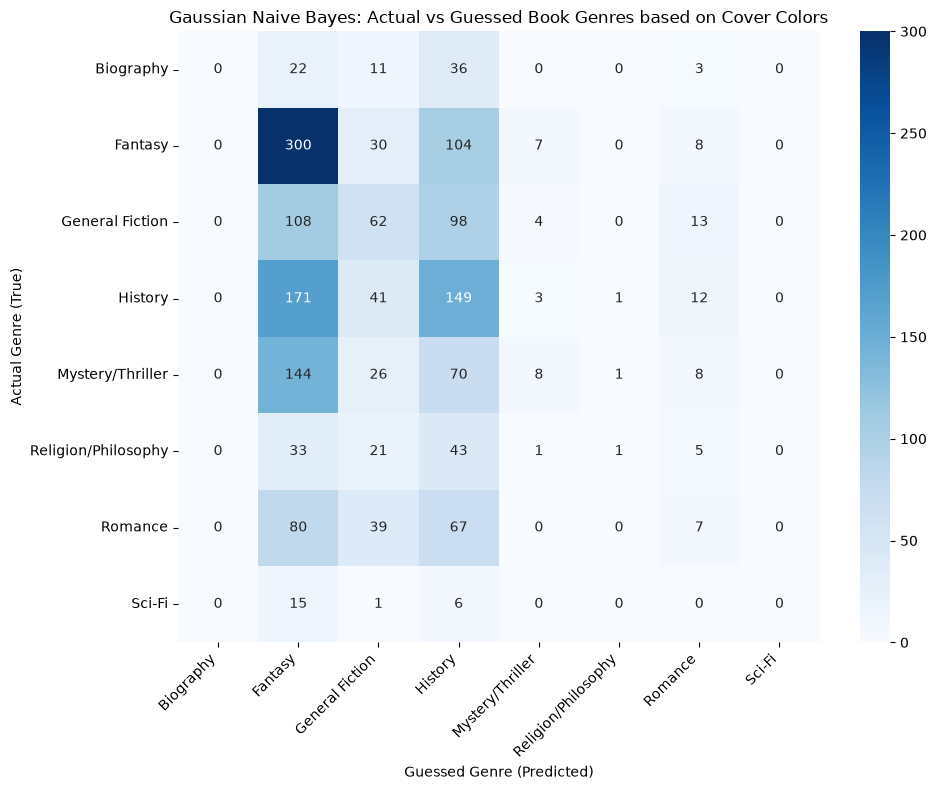

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=gnb.classes_)

# Create a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.xlabel('Guessed Genre (Predicted)')
plt.ylabel('Actual Genre (True)')
plt.title('Gaussian Naive Bayes: Actual vs Guessed Book Genres based on Cover Colors')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

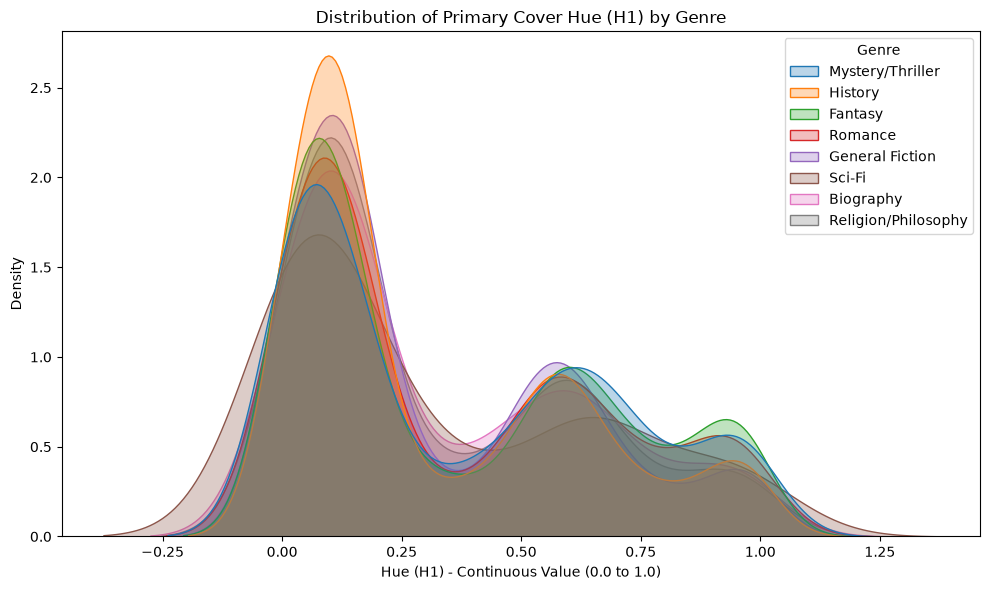

In [10]:
# Visualizing the distribution of the Primary Hue (H1) to show why Gaussian was chosen
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_model, x='H1', hue='Genre', common_norm=False, fill=True, alpha=0.3)
plt.title('Distribution of Primary Cover Hue (H1) by Genre')
plt.xlabel('Hue (H1) - Continuous Value (0.0 to 1.0)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
from IPython.display import HTML, display

# 1. Grab a new random sample of 6 books every time the cell is run
sample_books = df_model.sample(n=9)

# 2. Merge back with merged_df to get the image URLs and Hex colors
display_df = pd.merge(
    sample_books,
    merged_df[['ISBN13', 'Image-URL-M', 'color1_hex', 'color2_hex', 'color3_hex']],
    on='ISBN13',
    how='left'
).drop_duplicates(subset=['ISBN13'])

# 3. Build an HTML string to display them as a gallery
html_str = "<h3>Sample Books: Covers, Dominant Colors, and Genres</h3><div style='display: flex; flex-wrap: wrap; gap: 20px;'>"

for _, row in display_df.iterrows():
    title = row['Book-Title']
    genre = row['Genre']
    img_url = row['Image-URL-M']
    c1, c2, c3 = row['color1_hex'], row['color2_hex'], row['color3_hex']
    
    # HTML block for a single book card
    html_str += f"""
    <div style='width: 160px; border: 1px solid #ccc; padding: 10px; border-radius: 8px; text-align: center; background-color: #f9f9f9;'>
        <img src='{img_url}' style='height: 140px; object-fit: contain; margin-bottom: 10px;' onerror="this.src='https://via.placeholder.com/100x150?text=No+Cover'"/>
        <div style='font-size: 13px; font-weight: bold; height: 55px; overflow: hidden; margin-bottom: 5px;'>{title}</div>
        <div style='font-size: 12px; color: #444; margin-bottom: 10px;'>Genre:<br><b>{genre}</b></div>
        <div style='display: flex; justify-content: center; gap: 5px;'>
            <div style='width: 30px; height: 30px; background-color: {c1}; border: 1px solid #999; border-radius: 4px;' title='{c1}'></div>
            <div style='width: 30px; height: 30px; background-color: {c2}; border: 1px solid #999; border-radius: 4px;' title='{c2}'></div>
            <div style='width: 30px; height: 30px; background-color: {c3}; border: 1px solid #999; border-radius: 4px;' title='{c3}'></div>
        </div>
    </div>
    """

html_str += "</div>"

# 4. Render the HTML in the notebook output
display(HTML(html_str))

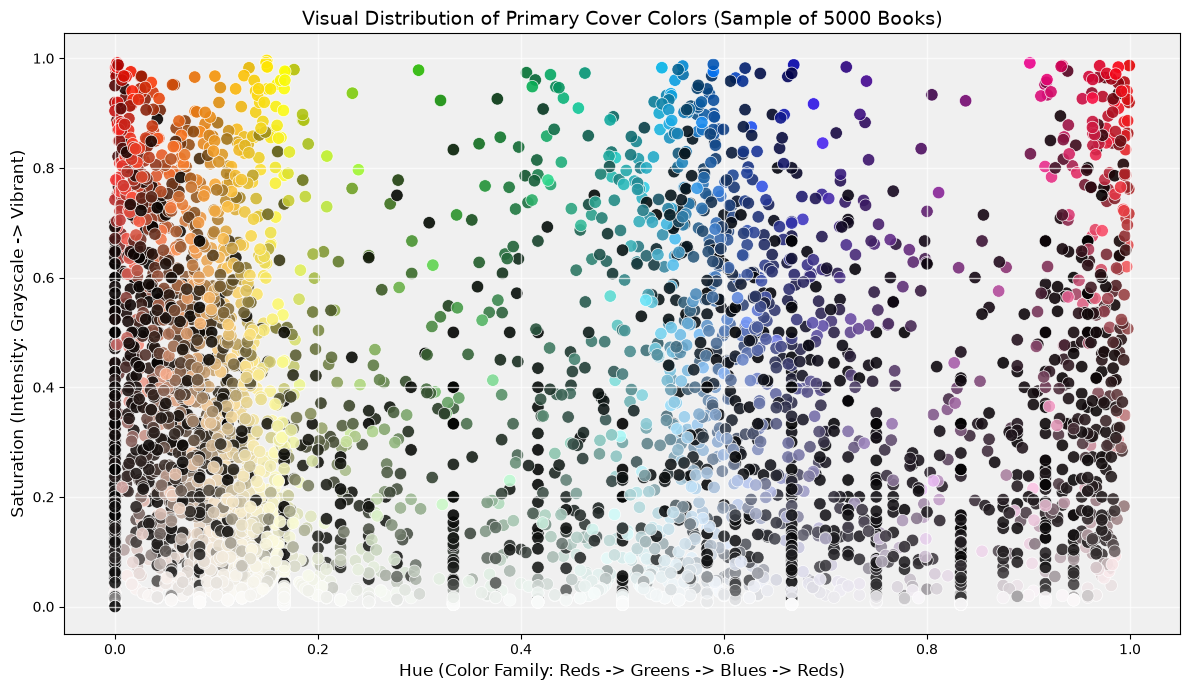

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Grab a random sample of 500 books to keep the chart from getting too crowded
sample_colors = df_model.sample(n=min(5000, len(df_model)), random_state=42)

# 2. Merge with merged_df to get the actual hex color codes back
color_df = pd.merge(
    sample_colors, 
    merged_df[['ISBN13', 'color1_hex']], 
    on='ISBN13', 
    how='left'
).drop_duplicates(subset=['ISBN13'])

# 3. Create the scatter plot
plt.figure(figsize=(12, 7))

# Plot Hue (H1) vs Saturation (S1), and use the actual hex color for the dot
plt.scatter(
    color_df['H1'], 
    color_df['S1'], 
    c=color_df['color1_hex'], 
    s=80, 
    alpha=0.9, 
    edgecolors='white',
    linewidth=0.5
)

plt.title('Visual Distribution of Primary Cover Colors (Sample of 5000 Books)', fontsize=14)
plt.xlabel('Hue (Color Family: Reds -> Greens -> Blues -> Reds)', fontsize=12)
plt.ylabel('Saturation (Intensity: Grayscale -> Vibrant)', fontsize=12)

# Set background to a light gray to make white/light book covers visible
plt.gca().set_facecolor('#f0f0f0') 
plt.grid(color='white', linestyle='-', linewidth=1, alpha=0.7)

plt.tight_layout()
plt.show()
